# ML Classification: Prediksi Perilaku Pembelian Pengunjung E-Commerce (KNN)

**Dataset**: UCI Online Shoppers Purchasing Intention (12.330 sesi kunjungan)
**Target**: `Revenue`  1 (pengunjung membeli) vs 0 (tidak membeli)
**Fitur**: aktivitas selama berkunjung (jumlah halaman, durasi, BounceRates, ExitRates, PageValues, dst.), bulan, tipe pengunjung, dan weekend
**Problem**: Klasifikasi biner, memprediksi apakah seorang pengunjung akan melakukan pembelian
**Model**: KNN dengan K = 5

## 1. Data Collection

Memuat data hasil preprocessing dari folder `data/processed/`. Data ini sudah di-encode, dibagi menjadi train dan test (80:20, stratified, `random_state = 42`), dan fitur numeriknya sudah di-scale. Jadi di sini kita tinggal memakainya.

In [21]:
import sys, os, json
sys.path.append("..")   #import config.py di folder induk

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config import RANDOM_STATE, OUTPUT_DIR

PROCESSED_DIR = "../data/processed"
os.makedirs(OUTPUT_DIR, exist_ok=True)
sns.set_style("whitegrid")

# Data scale
X_train_scaled = pd.read_csv(f"{PROCESSED_DIR}/X_train_scaled.csv")
X_test_scaled = pd.read_csv(f"{PROCESSED_DIR}/X_test_scaled.csv")

# Data belum scale 
X_train = pd.read_csv(f"{PROCESSED_DIR}/X_train.csv")
X_test = pd.read_csv(f"{PROCESSED_DIR}/X_test.csv")

# Target
y_train = pd.read_csv(f"{PROCESSED_DIR}/y_train.csv")["Revenue"]
y_test = pd.read_csv(f"{PROCESSED_DIR}/y_test.csv")["Revenue"]

print(f"Train: {X_train_scaled.shape}, Test: {X_test_scaled.shape}")
print("Jumlah fitur:", X_train_scaled.shape[1])
X_train_scaled.head()

Train: (9864, 28), Test: (2466, 28)
Jumlah fitur: 28


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,1.712088,3.624745,-0.395782,-0.244589,0.058405,0.083393,-0.353793,-0.612923,0.341014,3.663440,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.698294,-0.452341,-0.395782,-0.244589,-0.629459,-0.539163,0.360698,1.159262,-0.320268,-0.311499,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,-0.698294,-0.452341,-0.395782,-0.244589,-0.629459,-0.599504,-0.458865,0.136746,-0.320268,-0.311499,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.095698,1.429605,-0.395782,-0.244589,-0.331385,0.009963,-0.202751,-0.118883,0.716100,3.663440,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.698294,-0.452341,-0.395782,-0.244589,0.012548,-0.187989,-0.458865,-0.873776,2.625461,-0.311499,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


#### Cek Proporsi Kelas Target

In [22]:
print("Distribusi target di data train:")
print(y_train.value_counts())
print(f"Persentase pembeli (train): {y_train.mean()*100:.2f}%")

print("\nDistribusi target di data test:")
print(y_test.value_counts())
print(f"Persentase pembeli (test): {y_test.mean()*100:.2f}%")

# Akurasi 
baseline = (y_test == 0).mean()
print(f"\nAccuracy jika selalu menebak 'tidak beli': {baseline*100:.2f}%")

Distribusi target di data train:
Revenue
0    8338
1    1526
Name: count, dtype: int64
Persentase pembeli (train): 15.47%

Distribusi target di data test:
Revenue
0    2084
1     382
Name: count, dtype: int64
Persentase pembeli (test): 15.49%

Accuracy jika selalu menebak 'tidak beli': 84.51%


Pembeli hanya sekitar 15,5% dari seluruh data. Artinya model yang menebak "tidak beli" terus pun sudah punya accuracy sekitar 84,5%. Angka ini kita jadikan patokan: accuracy KNN baru bisa dibilang bagus kalau jauh di atas angka tersebut, dan tentu dengan accuracy saja tidak cukup untuk menilai model

## 2. Model Selection

Model yang dipakai adalah **KNN (K-Nearest Neighbors)** dengan **K = 5**.

Cara kerjanya: untuk setiap pengunjung baru, KNN mencari 5 pengunjung di data latih yang paling mirip (jarak paling dekat), lalu mengikuti suara terbanyak dari kelima tetangga itu. Kalau 3 dari 5 tetangga membeli, pengunjung baru diprediksi membeli.

Karena yang dihitung adalah **jarak** antar data, skala fitur sangat berpengaruh. Itulah mengapa data yang kita pakai merupakan data yang sudah discale

#### KNN (K = 5)

In [23]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 3. Model Evaluation

- Metrik: Accuracy, Precision, Recall, F1-score
- Confusion matrix
- Classification report
- Perbandingan KNN dengan dan tanpa scaling

#### KNN (K = 5)

In [24]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Evaluasi KNN
y_pred_knn = model_knn.predict(X_test_scaled)  #model KNN yg udh dilatih

print("=== KNN (K = 5) Evaluation ===")
print(f'\nAccuracy: {accuracy_score(y_test, y_pred_knn):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_knn, zero_division=0):.4f}')
print(f'Recall: {recall_score(y_test, y_pred_knn, zero_division=0):.4f}')
print(f'F1-score: {f1_score(y_test, y_pred_knn, zero_division=0):.4f}')

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

=== KNN (K = 5) Evaluation ===

Accuracy: 0.8719
Precision: 0.6435
Recall: 0.3874
F1-score: 0.4837

Confusion Matrix:
[[2002   82]
 [ 234  148]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      2084
           1       0.64      0.39      0.48       382

    accuracy                           0.87      2466
   macro avg       0.77      0.67      0.71      2466
weighted avg       0.86      0.87      0.86      2466



Confusion matrix di scikit-learn menggunakan format sebagai berikut:
- Baris => Actual
* Baris 1 = Actual Negative (tidak beli)
* Baris 2 = Actual Positive (beli)
- Kolom => Predicted
* Kolom 1 = Predicted Negative
* Kolom 2 = Predicted Positive

$$\begin{bmatrix} \text{True Negatives (TN)} & \text{False Positives (FP)} \\ \text{False Negatives (FN)} & \text{True Positives (TP)} \end{bmatrix}$$

#### Visualisasi Confusion Matrix

TN = 2002 | FP = 82 | FN = 234 | TP = 148


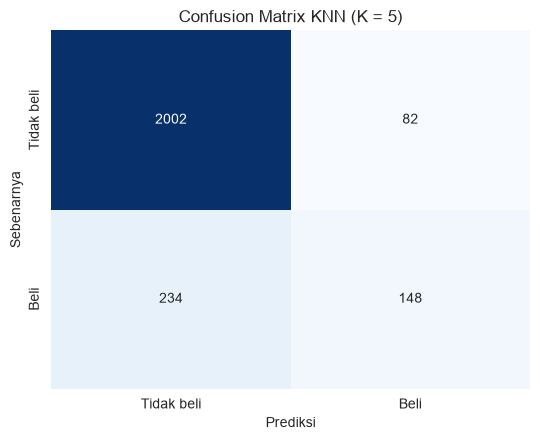

In [25]:
cm = confusion_matrix(y_test, y_pred_knn)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Tidak beli", "Beli"], yticklabels=["Tidak beli", "Beli"])
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.title("Confusion Matrix KNN (K = 5)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/08_cm_knn.png", dpi=150)
plt.show()

Arti:
- **TP**: pengunjung yang dipredict model beli dan benar benar membeli
- **FN**: pengunjung yang dipredict tidak beli tapi sebenarnya membeli
- **FP**: pengunjung yang dipredict beli tapi sebenarnya tidak membeli (meleset)
- **TN**: pengunjung yang dipredict tidak beli dan benar benar tidak membeli

#### KNN Tanpa Scaling vs Dengan Scaling

In [26]:
# KNN tanpa scaling
model_knn_raw = KNeighborsClassifier(n_neighbors=5)
model_knn_raw.fit(X_train, y_train)
y_pred_knn_raw = model_knn_raw.predict(X_test)

def hitung_metrik(y_true, y_hat):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat, zero_division=0),
        "Recall": recall_score(y_true, y_hat, zero_division=0),
        "F1-score": f1_score(y_true, y_hat, zero_division=0),
    }

#perbandingan
perbandingan = pd.DataFrame({
    "KNN tanpa scaling": hitung_metrik(y_test, y_pred_knn_raw),
    "KNN dengan scaling": hitung_metrik(y_test, y_pred_knn),
}).T.round(4)
perbandingan

,Accuracy,Precision,Recall,F1-score
KNN tanpa scaling,0.8500,0.5297,0.2801,0.3664
KNN dengan scaling,0.8719,0.6435,0.3874,0.4837


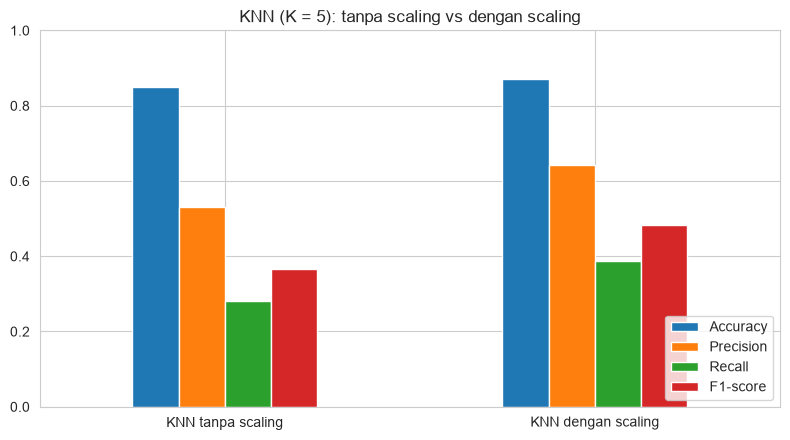

In [27]:
perbandingan.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("KNN (K = 5): tanpa scaling vs dengan scaling")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/09_knn_scaling.png", dpi=150)
plt.show()

## 4. Menyimpan Model dan Hasil

In [28]:
import joblib

joblib.dump(model_knn, f"{OUTPUT_DIR}/knn_model.pkl")
print("Model KNN berhasil disimpan sebagai knn_model.pkl")

m = hitung_metrik(y_test, y_pred_knn)
hasil_knn = {
    "model": "KNN (K=5)",
    "accuracy": round(m["Accuracy"], 4),
    "precision": round(m["Precision"], 4),
    "recall": round(m["Recall"], 4),
    "f1": round(m["F1-score"], 4),
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
}
with open(f"{OUTPUT_DIR}/hasil_knn.json", "w") as f:
    json.dump(hasil_knn, f, indent=2)

print("Hasil metrik berhasil disimpan sebagai hasil_knn.json")
hasil_knn

Model KNN berhasil disimpan sebagai knn_model.pkl
Hasil metrik berhasil disimpan sebagai hasil_knn.json


{'model': 'KNN (K=5)',
 'accuracy': 0.8719,
 'precision': 0.6435,
 'recall': 0.3874,
 'f1': 0.4837,
 'TN': 2002,
 'FP': 82,
 'FN': 234,
 'TP': 148}

## 5. Inference Menggunakan Model yang Telah Dilatih

In [29]:
# Load model dari file .pkl
model = joblib.load(f"{OUTPUT_DIR}/knn_model.pkl")

# Ambil 5 pengunjung pertama dari data test
sampel = X_test_scaled.head(5)
prediksi = model.predict(sampel)

print("Prediksi untuk 5 pengunjung:")
for i, (pred, asli) in enumerate(zip(prediksi, y_test.head(5))):
    status_pred = "Beli" if pred == 1 else "Tidak beli"
    status_asli = "Beli" if asli == 1 else "Tidak beli"
    print(f"Pengunjung {i+1}: prediksi = {status_pred} | sebenarnya = {status_asli}")

Prediksi untuk 5 pengunjung:
Pengunjung 1: prediksi = Tidak beli | sebenarnya = Tidak beli
Pengunjung 2: prediksi = Tidak beli | sebenarnya = Tidak beli
Pengunjung 3: prediksi = Beli | sebenarnya = Beli
Pengunjung 4: prediksi = Tidak beli | sebenarnya = Tidak beli
Pengunjung 5: prediksi = Tidak beli | sebenarnya = Tidak beli


# Melihat Versi Library yang Digunakan

In [30]:
%pip install -q session-info
import session_info

#tampilin library yg diimport saja dan versinya
session_info.show(dependencies=False, html=False)

Note: you may need to restart the kernel to use updated packages.
-----
joblib              1.6.0
matplotlib          3.11.2
numpy               2.5.4
pandas              3.0.6
seaborn             0.13.2
session_info        v1.0.1
sklearn             1.9.1
-----
IPython             9.17.1
jupyter_client      8.10.0
jupyter_core        5.9.1
-----
Python 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Windows-11-10.0.26300-SP0
-----
Session information updated at 2026-11-18 12:10



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Kesimpulan

KNN (K = 5) mendapat **accuracy 87,19%**, tapi angka ini menipu. Pembeli hanya sekitar 15% dari data, jadi menebak "tidak beli" terus pun sudah benar 84,51%.

precision dan recall
**Precision 64,35%** artinya kalau KNN bilang "beli", tebakannya benar sekitar 6 dari 10 kali. Tapi **recall cuma 38,74%**: dari 382 pembeli, hanya 148 yang berhasil ditemukan, sisanya 234 terlewat

Scaling juga terbukti penting. KNN menebak berdasarkan jarak, jadi fitur berangka besar seperti durasi bisa mendominasi fitur lain. Tanpa scaling, recall turun jadi 28,01%

Kalau perusahaan ingin menjaring sebanyak mungkin calon pembeli, recall harus diperhatikan, dan di sini KNN masih lemah